<font color="#a9a56c" size=2> **@Author: Arif Kasim Rozani - (Team Operation Badar)** </font>

# **<font color='Gold'>From Cave Paintings to File Writing: The Evolution of Communication</font>**



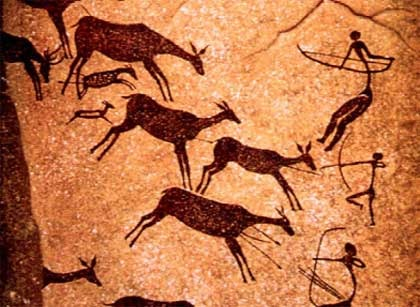


### **<font color='Gold'>Exploring Python's I/O Evolution from Primitive Expression to Modern Programming</font>**


---



#**File Handling in Python: A Comprehensive Tutorial with Examples**

File handling is essential for reading and writing data to files, enabling persistent storage. Python provides built-in functions and methods to handle files efficiently. This tutorial covers the fundamentals with examples.

---------


1. Opening a File
  
  Use the open() function to open a file. Specify the mode (read, write, append, etc.).


* Modes:

  * r: Read (default)

  * w: Write (Opens the file for writing. Creates the file if it doesn't exist, or overwrites it if it does.)

  * a: Append (Opens the file for appending. Creates the file if it doesn't exist, or adds to it if it does.)

  * x: Exclusive creation (fails if file exists)

  * b: Binary mode (Used with the other modes (e.g., "rb", "wb") for working with binary files.)

  * +: Update mode (Can be combined with other modes (e.g., "r+", "w+") to allow both reading and writing.)
<br>
------------------
<br>

###OK, Let's create a file in Colab.

<br>

**`w: Write mode`**. Opens the file for writing. Creates the file if it doesn't exist, or overwrites it if it does.

In [ ]:
file = open("new_file.txt", "w")

###Writing to Files:

To write to a file, open it in write ("w") or append ("a") mode.

write(string): Writes the given string to the file.

In [ ]:
file.write("Hello, world!\n")  # \n creates a new line
file.write("This is another line.\n")
file.close()

writelines(list): Writes a list of strings to the file.

In [ ]:
lines = ["Line 1: Karachi\n", "Line 2: Lahore\n", "Line 3: Peshawar\n"]
file = open("new_file.txt", "a") # run with mode w, and see the result
file.writelines(lines)
file.close()

#### Uptill now we have created a file with 'w' & 'a' mode and also write some lines in it.

#### Now let start reading the file what we have created earlier.

<font color=red>**Run the below line of code and see the error** </font> 😞

Explain why?

In [ ]:
file = open("my_file.txt", "r")

FileNotFoundError: [Errno 2] No such file or directory: 'my_file.txt'

So lets correct the name of the file 😀

In [ ]:
file = open("new_file.txt", "r")  # Opens "my_file.txt" in read mode ("r")

In [ ]:
content = file.read()
print(content)

Hello, world!
This is another line.
Line 1: Karachi
Line 2: Lahore
Line 3: Peshawar



In [ ]:
line = file.readline()
print(line)

#### <font color=red> **Nothing Printed ☹**</font>

###**<font color=blue>Here you need to know the concept of file pointer</font>**

---------

In Python, a `file pointer` (also called a `file cursor` or `file position indicator`) is an internal marker that keeps track of the `current position` in a file where the next read or write operation will occur. When you open a file, the file pointer is initialized to a specific position (`usually 0, the beginning of the file`), and it moves automatically as you read from or write to the file.

<br>

Key Concepts:
1. Starting Position:
  * r (read mode): Pointer starts at 0 (beginning of the file).
  * a (append mode): Pointer starts at the end of the file.
  * w (write mode): The file is truncated (erased), and the pointer starts at 0.

2. How It Moves:
  * When you read/write data, the pointer moves forward by the number of bytes/characters processed.
  * Example: Reading 10 characters moves the pointer 10 positions forward.

3. Manual Control:
  * Use seek(offset) to move the pointer to a specific byte position.
  * Use tell() to check the current pointer position.

###Move pointer back to start.

In [ ]:
file.seek(0)

0

###Check the file cursor/pointer position after running seek(0) method.

In [ ]:
print("Position after seek(0):", file.tell())

Position after seek(0): 0


In [ ]:
line = file.readline()
print(line)

Hello, world!



### readlines(): Reads all lines into a list.

In [ ]:
file.seek(0) # First move the pointer to the start

lines = file.readlines()
for line in lines:
    print(line)

Hello, world!

This is another line.

Line 1: Karachi

Line 2: Lahore

Line 3: Peshawar



In [ ]:
file = open("new_file.txt", "r")
for line in file:  # Iterating directly over the file reads line by line
    print(line.strip()) # .strip() removes leading/trailing whitespace

Hello, world!
This is another line.
Line 1: Karachi
Line 2: Lahore
Line 3: Peshawar


Closing Files:

* It's crucial to close files after you're finished with them.  This releases system resources and ensures that data is properly written to the disk.  The `close()` method is used for this:

In [ ]:
file.close()

### Additional Tips
- Exclusive Creation (x mode):

### Best Practices:
- Use `with` for automatic cleanup.
- Handle exceptions to avoid crashes.

In [ ]:
try:
    with open('unique.txt', 'x') as file:
        file.write('Created exclusively!')
        print("File created successfully!")
except FileExistsError:
    print("File already exists.")

File created successfully!


### <font color=gold>The `with` Statement (Context Manager): </font>

- The best practice for file handling is to use the `with` statement.  This ensures that the file is `automatically closed, even if errors occur`.

In [ ]:
with open("new_file.txt", "r") as file:
    content = file.read()
    print(content)
# File is automatically closed here

Hello, world!
This is another line.
Line 1: Karachi
Line 2: Lahore
Line 3: Peshawar



<font color=orange> The above cell use the `with` statement which close the file after use, let's validate it. </font>

<font color=red> **ValueError: I/O operation on closed file.** </font>


In [ ]:
file.tell() # will produce error, file is already closed because of with statement

ValueError: I/O operation on closed file.

### **Reading in chunks**

In [ ]:
with open("new_file.txt", "r") as file:
  print(file.tell())     # 0


  while True:
    content = file.read(10)
    if not content:
      print("End of file")
      break
    print(content)
    i+=1


           # reads 5 characters
  print(file.tell())     # now at position 5
  file.seek(0)           # back to start

0
Hello, wor
ld!
This i
s another 
line.
Line
 1: Karach
i
Line 2: 
Lahore
Lin
e 3: Pesha
war

End of file
84



### 🎯 `file.seek(offset, whence)` — _“Take me there!”_ 🧭

This command **moves the file pointer** to a new location in the file.

-   **`offset`** = how many **bytes** to move
    
-   **`whence`** = **from where** to start moving  
    _(defaults to 0 if not provided)_
    

----------

### 🧱 whence options:

| whence | Meaning          | Description                                                                  |   |
|--------|------------------|------------------------------------------------------------------------------|---|
| 0      | Start of file    | Move offset bytes from the beginning                                         |   |
| 1      | Current position | Move offset bytes forward/backward from where you are now                    |   |
| 2      | End of file      | Move offset bytes from the very end (use negative offsets to move backwards) |   |




* <font color=orange>You can only seek() in text mode with offsets from the beginning (i.e., whence=0).

* If you want to use whence=1 or whence=2, open the file in binary mode ('rb' or 'wb').
</font>

In [ ]:
with open("new_file.txt", "rb") as f:
    print("Tell: ", f.tell())        # ➤ 0
    f.seek(5)              # same as f.seek(5, 0)
    print("Tell: ", f.tell())        # ➤ 5

    f.seek(2, 1)           # move 2 bytes forward from current
    print("Tell: ", f.tell())        # ➤ 7

    f.seek(-3, 2)          # go 3 bytes *before* end of file
    print("Tell: ", f.tell())        # ➤ near the end


Tell:  0
Tell:  5
Tell:  7
Tell:  81


### Example: Copying a file

In [ ]:
def copy_file(source_path, destination_path):
    try:
        with open(source_path, "r") as source_file, open(destination_path, "w") as dest_file:
            for line in source_file:
                dest_file.write(line)
        print(f"File '{source_path}' copied to '{destination_path}' successfully.")
    except FileNotFoundError:
        print(f"Error: Source file '{source_path}' not found.")
    except Exception as e:
        print(f"An error occurred: {e}")

copy_file("unique.txt", "unique_copy.txt")

File 'unique.txt' copied to 'unique_copy.txt' successfully.


### Binary mode (Used with the other modes (e.g., "rb", "wb") for working with binary files.)

In [ ]:
def copy_image(source_path, destination_path):
    try:
        with open(source_path, 'rb') as source_file:
            with open(destination_path, 'wb') as destination_file:
                while True:
                    chunk = source_file.read(1024)  # Read in chunks
                    if not chunk:
                        break
                    destination_file.write(chunk)
        print(f"Image copied successfully from '{source_path}' to '{destination_path}'")

    except FileNotFoundError:
        print(f"Error: Source file '{source_path}' not found.")
    except Exception as e:
        print(f"An error occurred: {e}")

# Example usage (replace with your file paths)
copy_image("Apollo11.jpg", "Copy_Apollo11.jpg")


Image copied successfully from 'Apollo11.jpg' to 'Copy_Apollo11.jpg'


## Full Example: File Operations Demo

In [ ]:
# Create and write to a file
with open('demo.txt', 'w') as file:
    file.write('Python File Handling\n')
    file.write('Line 1\nLine 2\n')

# Read and print content
with open('demo.txt', 'r') as file:
    print("Content:")
    print(file.read())

# Append a new line
with open('demo.txt', 'a') as file:
    file.write('Appended line\n')

# Read lines using seek
with open('demo.txt', 'r+') as file:
    file.seek(0)
    print("First line:", file.readline())

Content:
Python File Handling
Line 1
Line 2

First line: Python File Handling



# Conclusion
- Python’s file handling is straightforward with **`open(), read(), write(), and close()`**. Always use the **`with`** statement for safety and leverage exception handling for robustness. Experiment with modes and methods to manage files effectively!

In [ ]:
# prompt: generate a comprehensive example of file handling using all the functions

# Create a file and write to it
with open('example.txt', 'w') as f:
  f.write("This is line 1.\n")
  f.write("This is line 2.\n")
  f.writelines(["This is line 3.\n", "This is line 4.\n"])

# Read the file and print its content
with open('example.txt', 'r') as f:
  content = f.read()
  print("--- Full Content ---")
  print(content)

# Read the file line by line and print each line
with open('example.txt', 'r') as f:
  print("--- Line by Line ---")
  for line in f:
    print(line, end='')

# Read a single line
with open('example.txt', 'r') as f:
  print("\n--- Readline ---")
  print(f.readline(), end='')

# Read all lines into a list
with open('example.txt', 'r') as f:
  lines = f.readlines()
  print("\n--- Readlines ---")
  for line in lines:
    print(line, end='')

# Append to the file
with open('example.txt', 'a') as f:
  f.write("This is appended line 1.\n")
  f.write("This is appended line 2.\n")

# Reading with seek and tell
with open('example.txt', 'r') as f:
  print("\n--- Seek and Tell ---")
  print("Current position:", f.tell())
  print("First line:", f.readline(), end="")
  print("Current position:", f.tell())
  f.seek(0)
  print("After seek(0):", f.tell())
  print("First line again:", f.readline(), end="")

# Demonstrating 'x' mode (exclusive creation)
try:
    with open('new_file.txt', 'x') as f:
        f.write("This is a new file created in 'x' mode.")
        print("new_file.txt created successfully!")
except FileExistsError:
    print("File 'new_file.txt' already exists!")

# Copy file example
def copy_file(source, destination):
  try:
    with open(source, 'r') as src, open(destination, 'w') as dest:
      for line in src:
        dest.write(line)
      print(f"'{source}' successfully copied to '{destination}'")
  except FileNotFoundError:
    print(f"Error: File not found '{source}'")
  except Exception as e:
    print(f"Error during copying: {e}")

copy_file("example.txt", "example_copy.txt")


--- Full Content ---
This is line 1.
This is line 2.
This is line 3.
This is line 4.

--- Line by Line ---
This is line 1.
This is line 2.
This is line 3.
This is line 4.

--- Readline ---
This is line 1.

--- Readlines ---
This is line 1.
This is line 2.
This is line 3.
This is line 4.

--- Seek and Tell ---
Current position: 0
First line: This is line 1.
Current position: 16
After seek(0): 0
First line again: This is line 1.
File 'new_file.txt' already exists!
'example.txt' successfully copied to 'example_copy.txt'
